# Notebook 01 — Dataset Preprocessing
## American Sign Language (ASL) Detection
---
Scans downloaded videos, plots the class distribution, shows sample frames,
encodes labels, splits into train/val/test, and saves metadata for the next notebooks.

In [1]:
import os, json, pickle, random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

random.seed(42)
np.random.seed(42)
os.makedirs('processed_data', exist_ok=True)
os.makedirs('models', exist_ok=True)
print('Libraries loaded.')

Libraries loaded.


In [2]:
# Scan data/raw/ — each subfolder is one ASL word
RAW_DIR = 'data/raw'
all_paths, all_labels = [], []

for word in sorted(os.listdir(RAW_DIR)):
    folder = os.path.join(RAW_DIR, word)
    if not os.path.isdir(folder):
        continue
    for fname in sorted(os.listdir(folder)):
        if fname.lower().endswith('.mp4'):
            all_paths.append(os.path.join(folder, fname))
            all_labels.append(word.replace('_', ' '))

class_names = sorted(set(all_labels))
NUM_CLASSES = len(class_names)

print(f'Total videos : {len(all_paths)}')
print(f'Classes ({NUM_CLASSES}): {class_names}')
print()
for cls in class_names:
    print(f'  {cls:15s}: {all_labels.count(cls)} videos')

Total videos : 889
Classes (30): ['ANGRY', 'ART', 'BAD', 'COME', 'EXCITED', 'FAMILY', 'FRIEND', 'GO', 'GOOD', 'HAPPY', 'HELLO', 'HELP', 'HOME', 'HURT', 'KNOW', 'LOVE', 'MORE', 'NO', 'PLEASE', 'SAD', 'SCARED', 'SORRY', 'STOP', 'THANK YOU', 'THINK', 'TIME', 'TIRED', 'WATER', 'WORK', 'YES']

  ANGRY          : 31 videos
  ART            : 29 videos
  BAD            : 29 videos
  COME           : 29 videos
  EXCITED        : 29 videos
  FAMILY         : 29 videos
  FRIEND         : 28 videos
  GO             : 30 videos
  GOOD           : 30 videos
  HAPPY          : 30 videos
  HELLO          : 31 videos
  HELP           : 30 videos
  HOME           : 30 videos
  HURT           : 29 videos
  KNOW           : 30 videos
  LOVE           : 29 videos
  MORE           : 30 videos
  NO             : 29 videos
  PLEASE         : 30 videos
  SAD            : 29 videos
  SCARED         : 31 videos
  SORRY          : 29 videos
  STOP           : 30 videos
  THANK YOU      : 30 videos
  THINK       

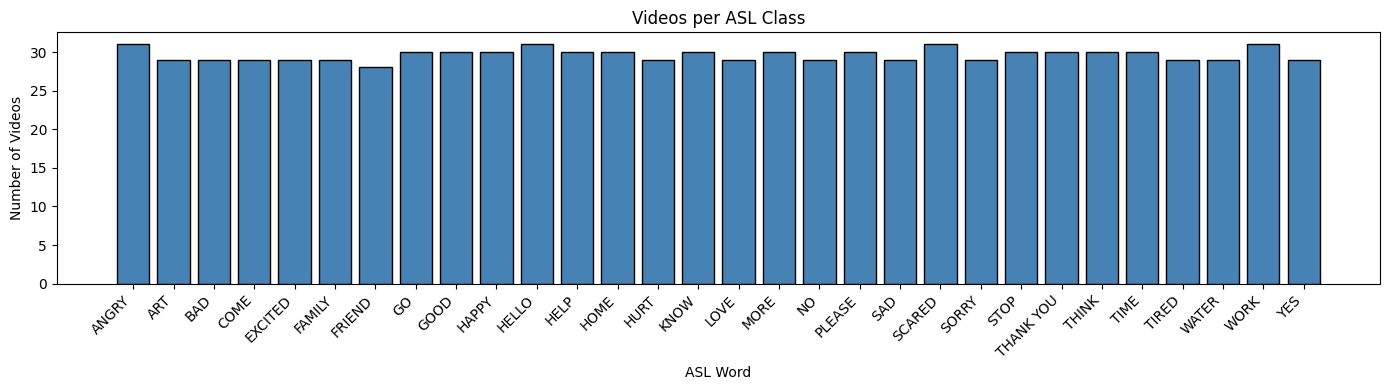

Min: 28  Max: 31  Avg: 29.6


In [3]:
# Bar chart of videos per class
counts = [all_labels.count(c) for c in class_names]

plt.figure(figsize=(14, 4))
plt.bar(class_names, counts, color='steelblue', edgecolor='black')
plt.title('Videos per ASL Class')
plt.xlabel('ASL Word')
plt.ylabel('Number of Videos')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('processed_data/class_distribution.png', dpi=150)
plt.show()
print(f'Min: {min(counts)}  Max: {max(counts)}  Avg: {np.mean(counts):.1f}')

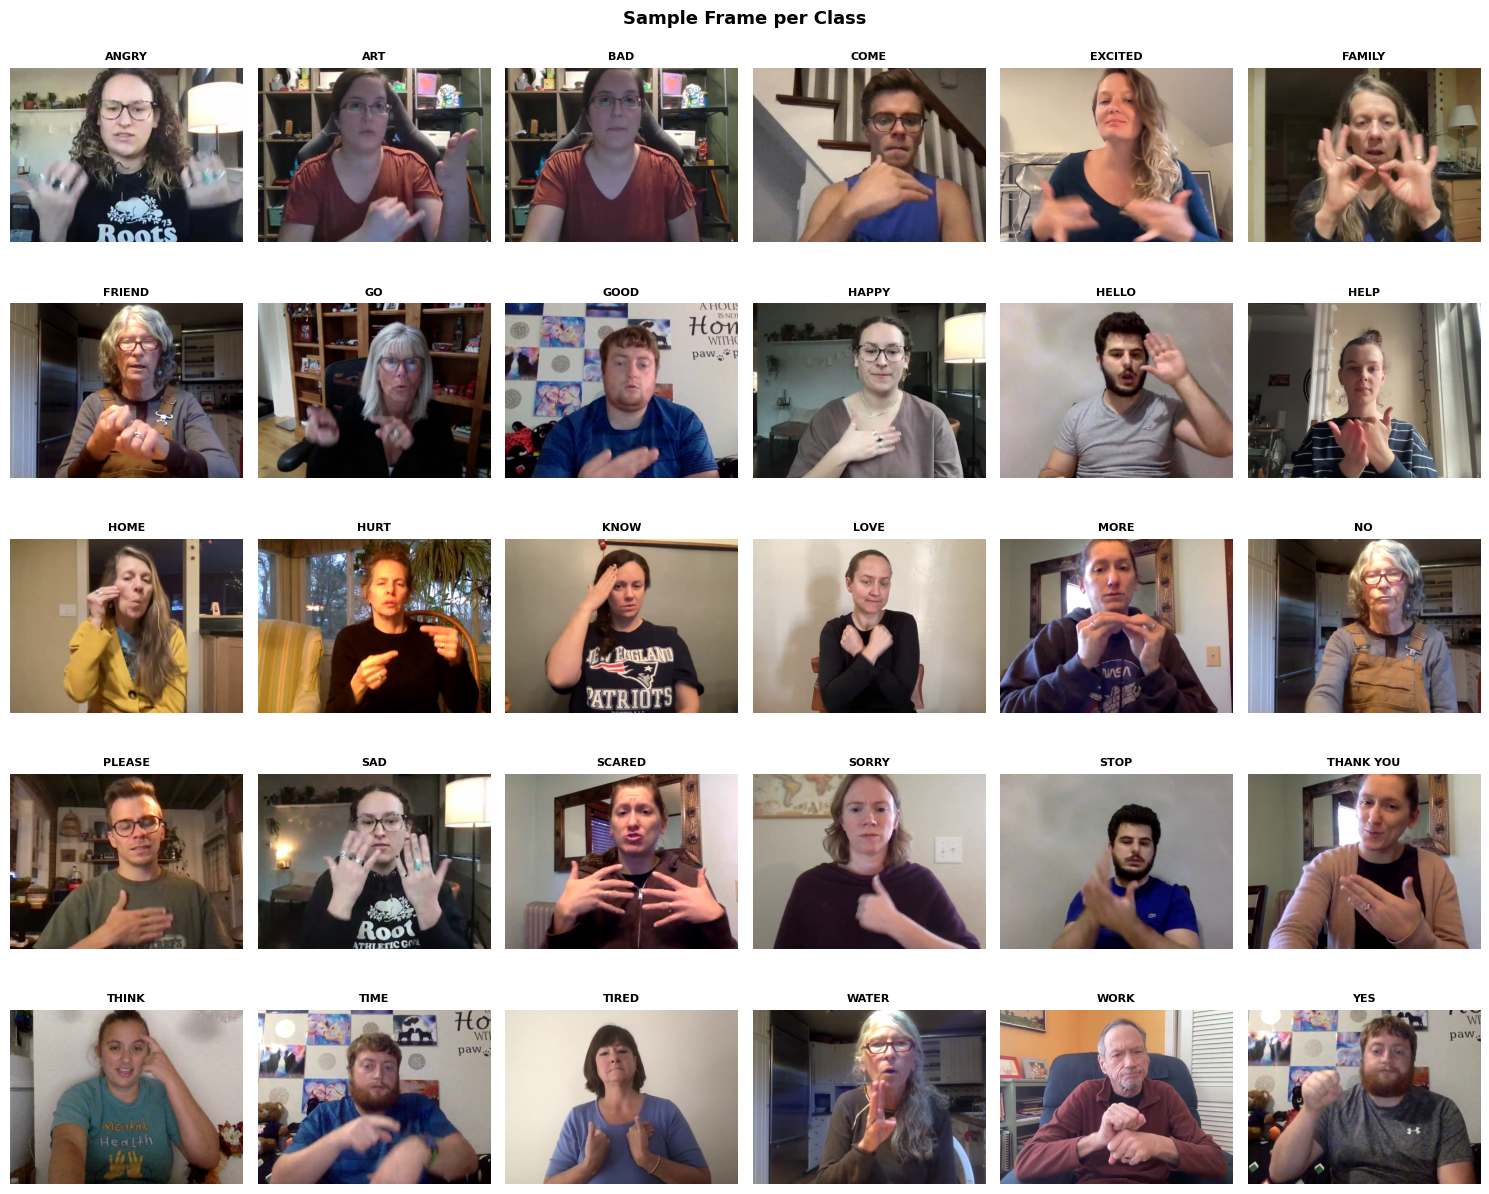

In [4]:
# Show one sample frame per class
def get_middle_frame(path):
    cap = cv2.VideoCapture(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, n // 2)
    ret, frame = cap.read()
    cap.release()
    if ret:
        return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    return np.zeros((100, 100, 3), np.uint8)

cols = 6
rows = (NUM_CLASSES + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
axes = np.array(axes).flatten()

for i, cls in enumerate(class_names):
    path = all_paths[all_labels.index(cls)]
    axes[i].imshow(get_middle_frame(path))
    axes[i].set_title(cls, fontsize=8, fontweight='bold')
    axes[i].axis('off')
for j in range(NUM_CLASSES, len(axes)):
    axes[j].axis('off')

plt.suptitle('Sample Frame per Class', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('processed_data/sample_frames.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# Encode labels and split: 5 val + 5 test per class, rest to train
le = LabelEncoder()
encoded = le.fit_transform(all_labels)

VAL_PER_CLASS = TEST_PER_CLASS = 5
train_idx, val_idx, test_idx = [], [], []

for cls_idx in range(NUM_CLASSES):
    idxs = [i for i, l in enumerate(encoded) if l == cls_idx]
    random.shuffle(idxs)
    test_idx  += idxs[:TEST_PER_CLASS]
    val_idx   += idxs[TEST_PER_CLASS : TEST_PER_CLASS + VAL_PER_CLASS]
    train_idx += idxs[TEST_PER_CLASS + VAL_PER_CLASS :]

print(f'Train: {len(train_idx)}  |  Val: {len(val_idx)}  |  Test: {len(test_idx)}')

Train: 589  |  Val: 150  |  Test: 150


In [6]:
# Save metadata for downstream notebooks
with open('processed_data/label_encoder.pkl', 'wb') as f:
    pickle.dump(le, f)

class_list = list(map(str, le.classes_))
with open('processed_data/class_names.json', 'w') as f:
    json.dump(class_list, f, indent=2)

for name, idxs in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    np.save(f'processed_data/{name}_paths.npy',  np.array([all_paths[i] for i in idxs]))
    np.save(f'processed_data/{name}_labels.npy', np.array([encoded[i]   for i in idxs]))

with open('processed_data/dataset_stats.json', 'w') as f:
    json.dump({'num_classes': NUM_CLASSES, 'class_names': class_list,
               'total_videos': len(all_paths), 'train_size': len(train_idx),
               'val_size': len(val_idx), 'test_size': len(test_idx)}, f, indent=2)

print('Saved all metadata.')
print('Proceed to Notebook 02.')

Saved all metadata.
Proceed to Notebook 02.
